In [1]:
%load_ext autoreload
%autoreload 2

# TASK 2 - Data Transformation

## Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import unicodedata
import datetime
import requests as r
from bs4 import BeautifulSoup
from tqdm import tqdm
import os
from IPython.display import clear_output

merged_dataset = '../dataset/merged.csv'
cleaned_dataset = '../dataset/cleaned.csv'

In [3]:
from typing import Tuple, Dict, Any

from sklearn.preprocessing import StandardScaler
import pandas


def __transform_single_features(dataset: pandas.DataFrame, transformation: str) -> Tuple[
    pandas.DataFrame, Dict[str, Any]]:
    match transformation:
        case "standard":
            transformed_dataset = dataset.copy().select_dtypes(exclude=["object", "category", "bool", "datetime64"])
            transformations = dict()

            for feature in transformed_dataset.columns:
                transformations[feature] = StandardScaler()
                transformed_feature = transformations[feature].fit_transform(transformed_dataset[[feature]]).squeeze()
                transformed_dataset = transformed_dataset.astype({feature: transformed_feature.dtype})
                transformed_dataset.loc[:, feature] = transformed_feature
        case _:
            raise ValueError(f"Unknown transformation: {transformation}")

    return transformed_dataset, transformations


def center_and_scale(dataset: pandas.DataFrame) -> Tuple[pandas.DataFrame, Dict[str, Any]]:
    """Shifts data to the origin: removes mean and scales by standard deviation all numeric features. Returns a copy of the dataset."""
    return __transform_single_features(dataset, "standard")


def drop_boolean(dataset: pandas.DataFrame) -> pandas.DataFrame:
    return dataset.select_dtypes(exclude="bool")

In [4]:
def normalize_text(text):
    text = unicodedata.normalize('NFD', text)
    text = ''.join(char for char in text if unicodedata.category(char) != 'Mn')
    return text

In [5]:
df_merged = pd.read_csv(merged_dataset, skipinitialspace=True)
df_merged.head()

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,...,delta,time,birth_year,weight,height,nationality,id_race,name_race,id_cyclist,name_cyclist
0,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,0,sean-kelly,...,0.0,04:02:24,1956.0,77.0,180.0,Ireland,tour-de-france/1978/stage-6,Tour de France,sean-kelly,Sean Kelly
1,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,1,gerrie-knetemann,...,0.0,04:02:24,1951.0,NaN,NaN,Netherlands,tour-de-france/1978/stage-6,Tour de France,gerrie-knetemann,Gerrie Knetemann
2,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,2,rene-bittinger,...,0.0,04:02:24,1954.0,69.0,174.0,France,tour-de-france/1978/stage-6,Tour de France,rene-bittinger,René Bittinger
3,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,3,joseph-bruyere,...,0.0,04:02:24,1948.0,NaN,NaN,Belgium,tour-de-france/1978/stage-6,Tour de France,joseph-bruyere,Joseph Bruyère
4,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1978-07-05,4,sven-ake-nilsson,...,0.0,04:02:24,1951.0,63.0,172.0,Sweden,tour-de-france/1978/stage-6,Tour de France,sven-ake-nilsson,Sven-Åke Nilsson


In [6]:
# normalize race name
df_merged['name_race_norm'] = df_merged['name_race'].apply(normalize_text)

Let's see the missing data inside our merged dataset.

<Axes: >

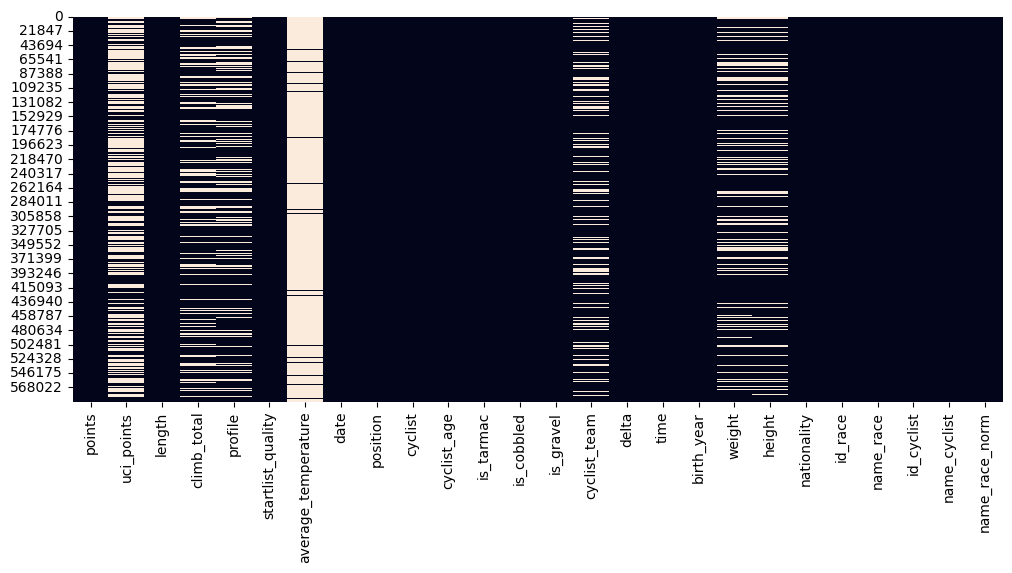

In [7]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

As can be seen from the map we have some missing values on these features:
- `uci_points`
- `climb_total`
- `profile`
- `average_temperature`
- `cyclist_team`
- `weight`
- `height`

Let's see again the correlation matrix

In [8]:
"""Dataset understanding utilities."""
from typing import Dict
import pandas


def correlations(dataset: pandas.DataFrame) -> pandas.DataFrame:
    correlations_dictionary = {
        correlation_type: dataset.corr(numeric_only=True, method=correlation_type)
        for correlation_type in ("kendall", "pearson", "spearman")
    }
    for i, k in enumerate(correlations_dictionary.keys()):
        correlations_dictionary[k].loc[:, "correlation_type"] = k
    correlations_matrix = pandas.concat(correlations_dictionary.values())

    return correlations_matrix

In [9]:
df_numerical_features = df_merged.dropna().select_dtypes(include=['number'])
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_numerical_features)
correlations = correlations(normalized_dataset)
correlations

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height,correlation_type
points,1.000000,0.860994,0.200637,0.044654,-0.040243,0.560150,0.151729,0.016371,0.049198,0.133532,-0.065519,0.085092,0.040916,kendall
uci_points,0.860994,1.000000,0.188210,0.042924,-0.037369,0.534801,0.066974,0.007763,0.043275,0.115837,-0.041739,0.072269,0.035921,kendall
length,0.200637,0.188210,1.000000,0.064639,-0.128981,0.035504,-0.097622,0.000370,0.000076,-0.062641,-0.014964,0.007348,0.002690,kendall
climb_total,0.044654,0.042924,0.064639,1.000000,0.584836,0.034792,-0.084943,-0.023128,0.004645,0.403906,-0.015898,-0.045566,-0.027229,kendall
profile,-0.040243,-0.037369,-0.128981,0.584836,1.000000,0.017621,-0.022638,-0.009198,0.004913,0.420424,-0.008978,-0.022062,-0.012471,kendall
startlist_quality,0.560150,0.534801,0.035504,0.034792,0.017621,1.000000,0.222601,0.054819,0.063040,0.097472,-0.066490,0.081323,0.040652,kendall
average_temperature,0.151729,0.066974,-0.097622,-0.084943,-0.022638,0.222601,1.000000,0.017471,0.025604,0.024801,-0.050242,0.046658,0.024332,kendall
position,0.016371,0.007763,0.000370,-0.023128,-0.009198,0.054819,0.017471,1.000000,0.016919,0.342360,-0.016646,0.157936,0.087734,kendall
cyclist_age,0.049198,0.043275,0.000076,0.004645,0.004913,0.063040,0.025604,0.016919,1.000000,0.014984,-0.957688,0.053042,-0.023453,kendall
delta,0.133532,0.115837,-0.062641,0.403906,0.420424,0.097472,0.024801,0.342360,0.014984,1.000000,-0.022803,0.130283,0.066714,kendall


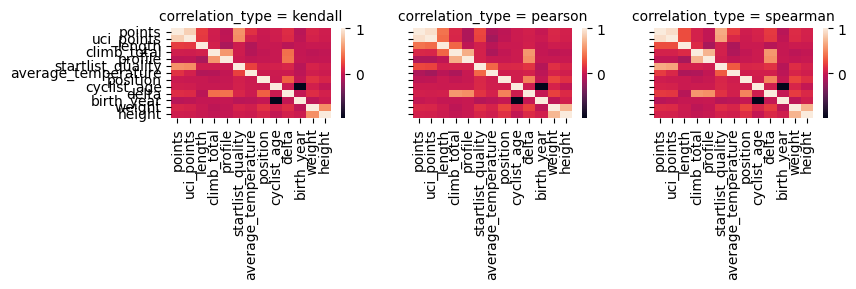

In [10]:
g = sns.FacetGrid(correlations, col="correlation_type")
g.map_dataframe(lambda data, color: sns.heatmap(data[data.columns[:-1]]))

<Axes: >

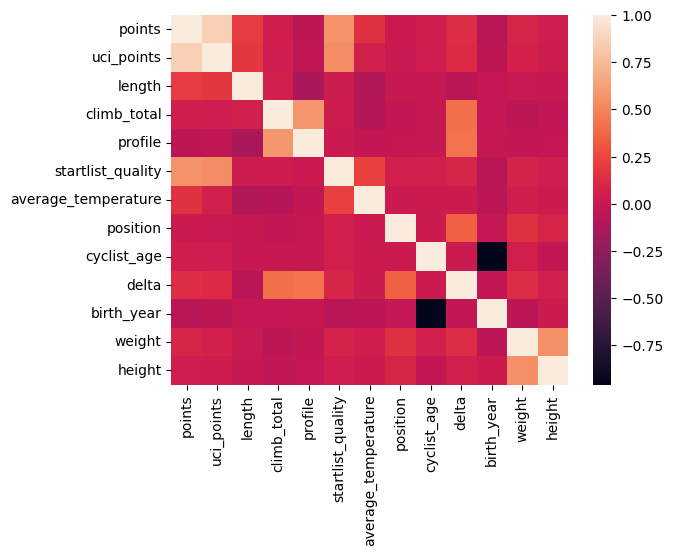

In [11]:
kendall_correlation = correlations.iloc[range(correlations.shape[1]-1), :].drop("correlation_type", axis="columns")
sns.heatmap(kendall_correlation)

In the data undertanding notebook, we saw that there are some features that are not so informative for our task. So in order to do an initial cleaning, we decide to delete `is_cobbled` and `is_gravel` since the value are all setted to false.

In [12]:
del df_merged['is_cobbled']
del df_merged['is_gravel']

Now we try to do some imputation in order to fill some missing values. Now we focus on `uci_points` feature. The latter give us another point of view to analyze the points obtained in a race, because takes into account even the difficulty of the race. By doing some research it seems that this points is obtained by linear combination of the points, the type of race and the position obtained. Therefore, we group the race by name and date and then we calculate uci_points_ratio, i.e. $\frac{\text{points}}{\text{uci\_points}}$

In [13]:
# Add the new column
df_merged['points_to_uci_ratio'] = df_merged.apply(
    lambda row: row['uci_points'] / row['points'] if pd.notnull(row['uci_points']) and row['uci_points'] != 0 else None,
    axis=1
)

df_merged[df_merged['position']==1][df_merged['name_race_norm']=='Tour de France'].dropna(subset=['points_to_uci_ratio'])[['points_to_uci_ratio', 'date']].sort_values(by='date').groupby('points_to_uci_ratio')['date'].agg(['count']).reset_index()

df_merged['date'] = pd.to_datetime(df_merged['date'])
race_dict = {}
for race_name, group in df_merged.groupby('name_race_norm'):
    group_sorted = group.sort_values(by='date')
    entries = []
    for ratio, ratio_group in group_sorted.groupby('points_to_uci_ratio'):
        min_date_row = ratio_group.iloc[0]
        max_date_row = ratio_group.iloc[-1]
        entries.append({"points_to_uci_ratio": ratio, "date": min_date_row['date'].strftime('%Y-%m-%d')})
        if min_date_row['date'] != max_date_row['date']:
            entries.append({"points_to_uci_ratio": ratio, "date": max_date_row['date'].strftime('%Y-%m-%d')})
    race_dict[race_name] = entries



/tmp/ipykernel_36328/1466651562.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_merged[df_merged['position']==1][df_merged['name_race_norm']=='Tour de France'].dropna(subset=['points_to_uci_ratio'])[['points_to_uci_ratio', 'date']].sort_values(by='date').groupby('points_to_uci_ratio')['date'].agg(['count']).reset_index()


In [14]:
keys = list(race_dict.keys())
for race in keys:
    if len(race_dict[race]) == 0:
        del race_dict[race]

In [15]:
df_merged['uci_points'].isna().sum()

np.int64(338779)

In [16]:
def get_closest_uci_points(row):
    if pd.notnull(row['uci_points']):
        return row['uci_points']
    if row['name_race_norm'] in race_dict:
        uci_points_list = race_dict[row['name_race_norm']]
        for i in range(len(uci_points_list) - 1):
            prev_date_in_dict = datetime.datetime.strptime(uci_points_list[i]["date"], "%Y-%m-%d")
            next_date_in_dict = datetime.datetime.strptime(uci_points_list[i + 1]["date"], "%Y-%m-%d")
            date_comparing = row['date']
            if date_comparing >= prev_date_in_dict and date_comparing <= next_date_in_dict:
                row['uci_points'] = uci_points_list[i]['points_to_uci_ratio'] * row['points']
    return row['uci_points']

df_merged['uci_points'] = df_merged.apply(get_closest_uci_points, axis=1)


In [17]:
df_merged['uci_points'].isna().sum()

np.int64(335982)

Now we focus on `weight` and `height` features. In order to fill some missing values, we try to fill them by using the average of them. Precisely, given a specific height we obtain the average of weight. We use this strategy even for the weight.

In [18]:
weight_by_height = df_merged.groupby('height')['weight'].mean()
height_by_weight = df_merged.groupby('weight')['height'].mean()

def fill_height(row, weight_by_height):
    if pd.isna(row['height']) or pd.isnull(row['height']):
        avg_weight = row['weight']
        closest_height = weight_by_height.sub(avg_weight).abs().idxmin() if pd.notna(avg_weight) else None
        return closest_height
    return row['height']

def fill_weight(row, height_by_weight):
    if pd.isna(row['weight']) or pd.isnull(row['weight']):
        weight = row['height']
        closest_weight = height_by_weight.sub(weight).abs().idxmin() if pd.notna(weight) else None
        return closest_weight
    return row['weight']

df_merged['height'] = df_merged.apply(fill_height, axis=1, weight_by_height= weight_by_height)
df_merged['weight'] = df_merged.apply(fill_weight, axis=1, height_by_weight= height_by_weight)

<Axes: >

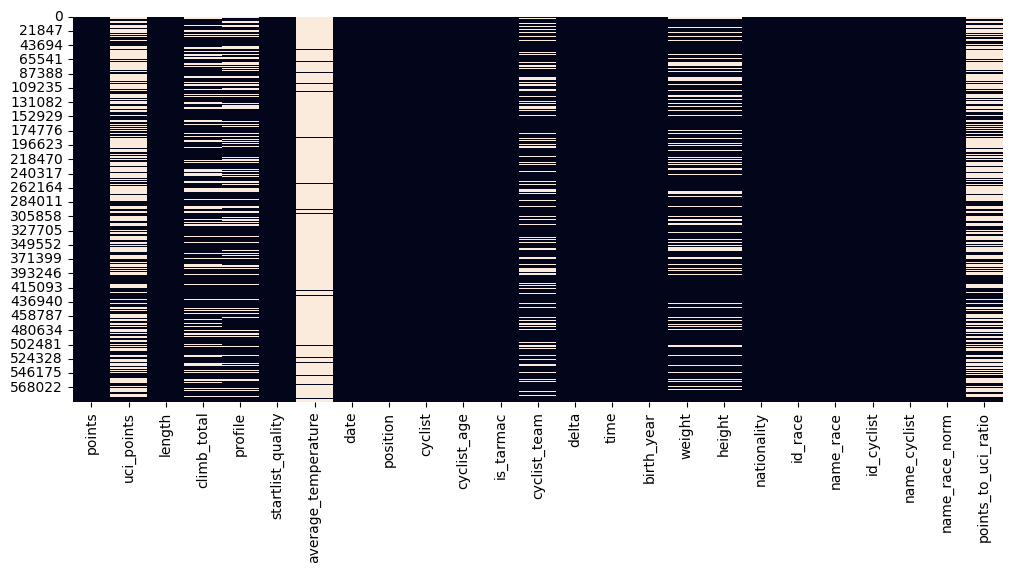

In [19]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

Finally we try to fill the missing values of `profile` and `climb_total`

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import OneHotEncoder

# Step 1: Separate rows with and without 'profile'
train_data = df_merged.dropna(subset=['profile'])  # Rows with known 'profile'
missing_data = df_merged[df_merged['profile'].isna()]    # Rows with missing 'profile'

# Step 2: Split training data into features and target
X = train_data[['length', 'climb_total']].fillna(0)  # Fill missing feature values with 0 (or use imputation)
y = train_data['profile'].astype(int)

# Step 3: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [21]:
y_pred = classifier.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test, y_pred)}")

Accuracy: 0.988373804267844
Classification Report:
              precision    recall  f1-score   support

           1       0.99      0.99      0.99     26381
           2       0.99      0.99      0.99     25393
           3       0.97      0.97      0.97     10227
           4       1.00      0.98      0.99      8592
           5       0.99      0.99      0.99     17742

    accuracy                           0.99     88335
   macro avg       0.99      0.99      0.99     88335
weighted avg       0.99      0.99      0.99     88335



In [22]:
for idx, row in missing_data.iterrows():
    if not (pd.isna(row['length']) or pd.isna(row['climb_total'])):
        # Prepare a single-row DataFrame for prediction
        X_single = pd.DataFrame([row[['length', 'climb_total']]])
        # Predict and update the missing value
        df_merged.loc[idx, 'profile'] = classifier.predict(X_single)[0]

<Axes: >

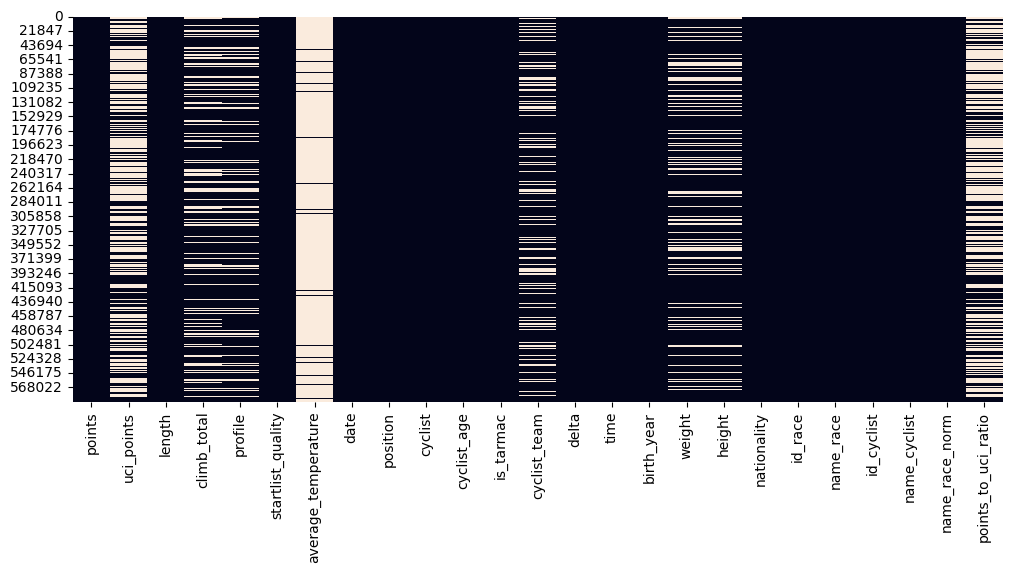

In [23]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

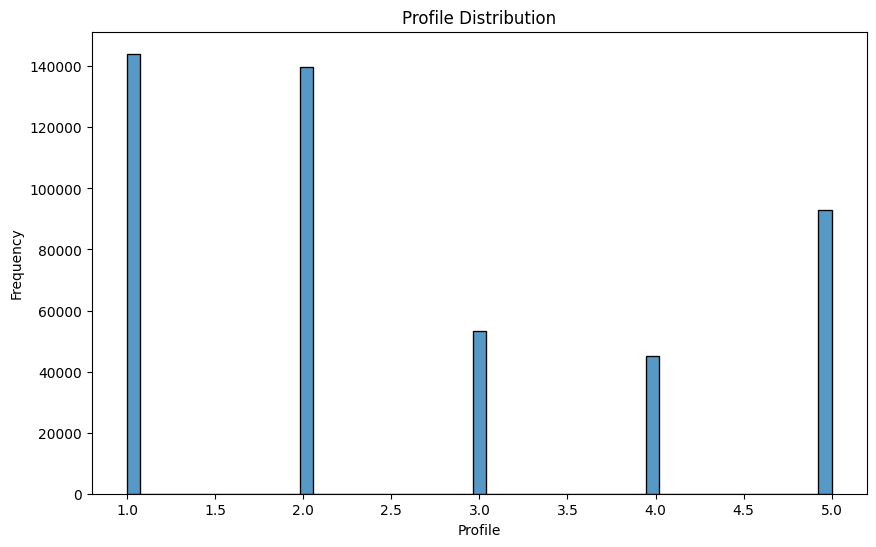

In [24]:
plt.figure(figsize=(10, 6))
sns.histplot(df_merged['profile'].dropna())
plt.title('Profile Distribution')
plt.xlabel('Profile')
plt.ylabel('Frequency')
plt.show()

The only two features that won't try to impute are `average_temperature` and `cyclist_teams`. The reason is that `average_temperature` there are too missing values and in our opinion we risks to add a lot of noise. On the other hand, for `cyclist_teams` feature we didn't find a strategy to fill them. The only way, in our opinion, is to apply the scraping.  

In data understanding notebook, we even see that `delta` feature isn't consistent with `position` feature. We firmly believe that the format of delta values isn't so specific because in the races even milliseconds are important. So decide to delete this feature. 

<Axes: >

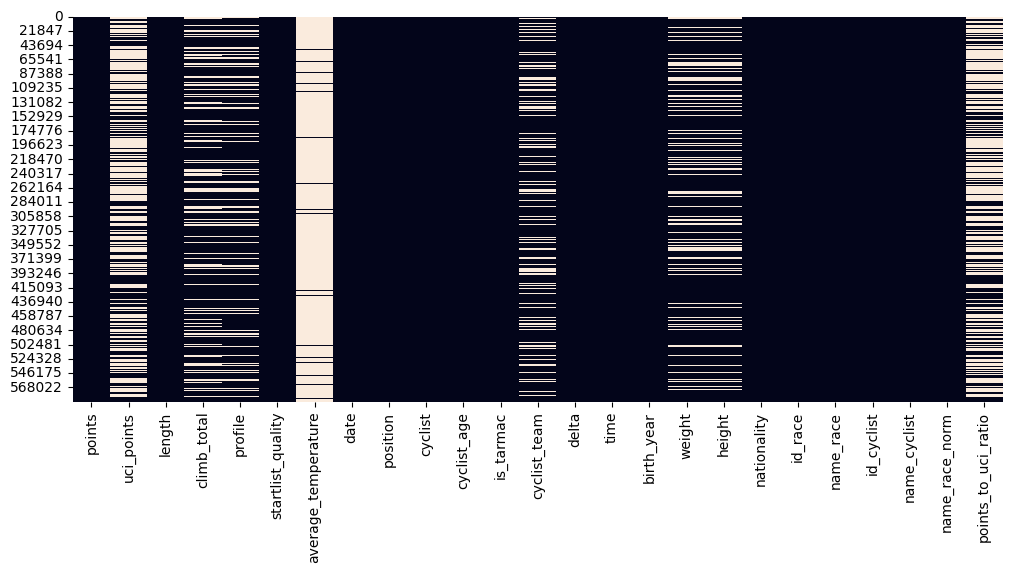

In [25]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_merged.isnull(), cbar=False, xticklabels=True, ax=ax)

In [26]:
del df_merged['points_to_uci_ratio']

In [27]:

# def add_nan_flags(df):
#     """
#     Adds a column `is_<feature>_nan` for each feature in the DataFrame
#     that contains NaN values. The new column marks `True` if the row 
#     has a NaN value in that feature, otherwise `False`.
    
#     Parameters:
#         df (pd.DataFrame): Input DataFrame.

#     Returns:
#         pd.DataFrame: DataFrame with additional NaN flag columns.
#     """
#     # Iterate through all columns in the DataFrame
#     for col in df.columns:
#         if df[col].isna().any():  # Check if the column contains NaN values
#             # Add a new column indicating NaN presence for the feature
#             df[f'is_{col}_nan'] = df[col].isna()
#     return df


# df_merged = add_nan_flags(df_merged)
# df_merged

## Outlier detection

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height
0,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.533334,-1.682270,-0.496219,-1.879430,1.392699,0.047648
1,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.512675,-0.385465,-0.496219,-2.312855,NaN,NaN
2,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.492015,-1.163548,-0.496219,-2.052800,0.105351,-0.908599
3,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.471356,0.392619,-0.496219,-2.572911,NaN,NaN
4,0.198003,NaN,-0.073997,-0.893698,-1.065984,0.36743,NaN,-1.450697,-0.385465,-0.496219,-2.312855,-0.860160,-1.227348


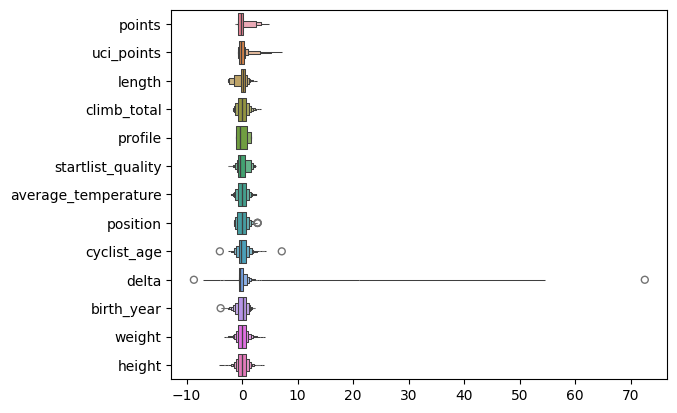

In [28]:
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_merged)

sns.boxenplot(normalized_dataset, orient="h")
normalized_dataset.head()

/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7065: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7066: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


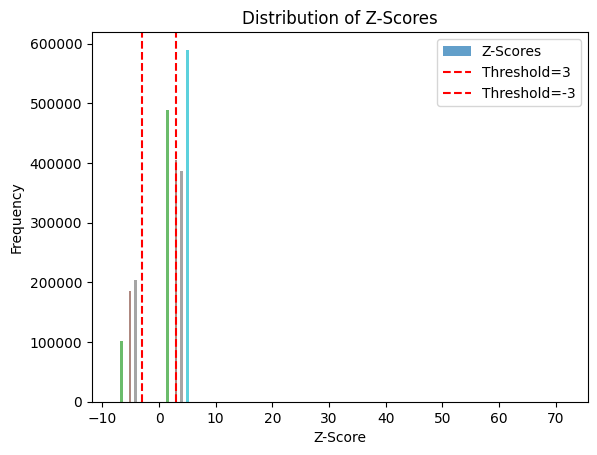

In [29]:
from scipy.stats import zscore

cop = df_merged.copy().select_dtypes(include="number")

z_scores = zscore(cop)
plt.hist(z_scores, alpha=0.7, label='Z-Scores')
plt.axvline(x=3, color='red', linestyle='--', label='Threshold=3')
plt.axvline(x=-3, color='red', linestyle='--', label='Threshold=-3')
plt.legend()
plt.title("Distribution of Z-Scores")
plt.xlabel("Z-Score")
plt.ylabel("Frequency")
plt.show()

In [30]:
outliers = (z_scores > 3).any(axis=1)
outliers_zscore = df_merged[outliers]
print("Outliers detected using Z-Score:")
print(outliers_zscore)

Outliers detected using Z-Score:
        points  uci_points    length  climb_total  profile  startlist_quality  \
16625    100.0         NaN  204500.0       3000.0      5.0               1470   
26891     50.0         NaN  178800.0          NaN      NaN                873   
30751    100.0         NaN  251000.0       5000.0      4.0               1492   
31635     50.0         NaN  193000.0          NaN      NaN                442   
31636     50.0         NaN  193000.0          NaN      NaN                442   
...        ...         ...       ...          ...      ...                ...   
584357    80.0        16.0  236000.0       5113.0      5.0                861   
584358    80.0        16.0  236000.0       5113.0      5.0                861   
586540    80.0        16.0  203000.0       2413.0      3.0                892   
586554    80.0        16.0  203000.0       2413.0      3.0                892   
586560    80.0        16.0  203000.0       2413.0      3.0                89

In [31]:
from sklearn.neighbors import LocalOutlierFactor

# Initialize Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20)
outlier_labels = lof.fit_predict(cop.fillna(0)) 

# Extract outliers
outliers_knn = cop[outlier_labels == -1]

print("Outliers detected using k-NN:")
print(outliers_knn)

Outliers detected using k-NN:
        points  uci_points    length  climb_total  profile  startlist_quality  \
1        100.0         NaN  162000.0       1101.0      1.0               1241   
3        100.0         NaN  162000.0       1101.0      1.0               1241   
105      100.0         NaN  162000.0       1101.0      1.0               1241   
137       80.0       100.0  196000.0       5575.0      5.0                821   
138       80.0       100.0  196000.0       5575.0      5.0                821   
...        ...         ...       ...          ...      ...                ...   
589663    50.0        50.0  136400.0       1880.0      2.0               1045   
589664    50.0        50.0  136400.0       1880.0      2.0               1045   
589665    50.0        50.0  136400.0       1880.0      2.0               1045   
589666    50.0        50.0  136400.0       1880.0      2.0               1045   
589667    50.0        50.0  136400.0       1880.0      2.0               1045  

In [32]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
outlier_predictions = iso_forest.fit_predict(cop.fillna(0))  # -1 indicates an outlier

# Extract outliers
outliers_iso = cop[outlier_predictions == -1]

print("Outliers detected using Isolation Forest:")
print(outliers_iso)

Outliers detected using Isolation Forest:
        points  uci_points    length  climb_total  profile  startlist_quality  \
245       80.0       100.0  196000.0       5575.0      5.0                821   
549      100.0       120.0  192900.0       3743.0      3.0               1551   
550      100.0       120.0  192900.0       3743.0      3.0               1551   
552      100.0       120.0  192900.0       3743.0      3.0               1551   
554      100.0       120.0  192900.0       3743.0      3.0               1551   
...        ...         ...       ...          ...      ...                ...   
589448   275.0         NaN  273000.0          NaN      1.0                808   
589449   275.0         NaN  273000.0          NaN      1.0                808   
589458   275.0         NaN  273000.0          NaN      1.0                808   
589486    50.0         NaN  185000.0          NaN      NaN                779   
589513    50.0         NaN  185000.0          NaN      NaN         

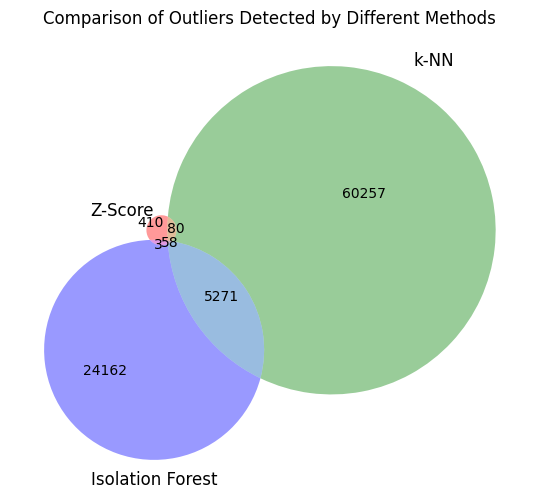

In [34]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

zscore_indices = set(outliers_zscore.index)
knn_indices = set(outliers_knn.index)
iso_indices = set(outliers_iso.index)

cop['outlier_zscore'] = cop.index.isin(zscore_indices).astype(int)
cop['outlier_knn'] = cop.index.isin(knn_indices).astype(int)
cop['outlier_iso'] = cop.index.isin(iso_indices).astype(int)
cop['any_outlier'] = cop[['outlier_zscore', 'outlier_knn', 'outlier_iso']].any(axis=1).astype(int)

plt.figure(figsize=(8, 6))
venn3([zscore_indices, knn_indices, iso_indices], ('Z-Score', 'k-NN', 'Isolation Forest'))
plt.title("Comparison of Outliers Detected by Different Methods")
plt.show()

In [35]:
cop

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,delta,birth_year,weight,height,outlier_zscore,outlier_knn,outlier_iso,any_outlier
0,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,0,22.0,0.0,1956.0,77.0,180.0,0,0,0,0
1,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,1,27.0,0.0,1951.0,NaN,NaN,0,1,0,1
2,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,2,24.0,0.0,1954.0,69.0,174.0,0,0,0,0
3,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,3,30.0,0.0,1948.0,NaN,NaN,0,1,0,1
4,100.0,NaN,162000.0,1101.0,1.0,1241,NaN,4,27.0,0.0,1951.0,63.0,172.0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589860,80.0,16.0,8400.0,60.0,1.0,878,NaN,192,25.0,80.0,1985.0,65.0,167.0,0,0,0,0
589861,80.0,16.0,8400.0,60.0,1.0,878,NaN,193,28.0,82.0,1982.0,61.0,173.0,0,0,0,0
589862,80.0,16.0,8400.0,60.0,1.0,878,NaN,194,24.0,83.0,1986.0,59.0,171.0,0,0,0,0
589863,80.0,16.0,8400.0,60.0,1.0,878,NaN,195,38.0,90.0,1972.0,67.0,171.0,0,0,0,0


In [36]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso']).fillna(0))

cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]


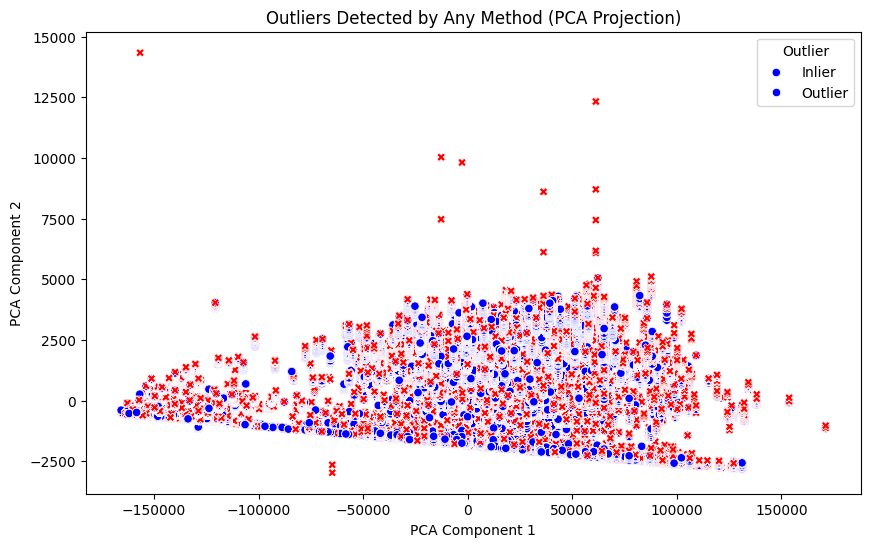

In [37]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cop, x='pca1', y='pca2', hue='any_outlier', style='any_outlier', palette={0: 'blue', 1: 'red'})
plt.title("Outliers Detected by Any Method (PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Outlier", labels=["Inlier", "Outlier"])
plt.show()

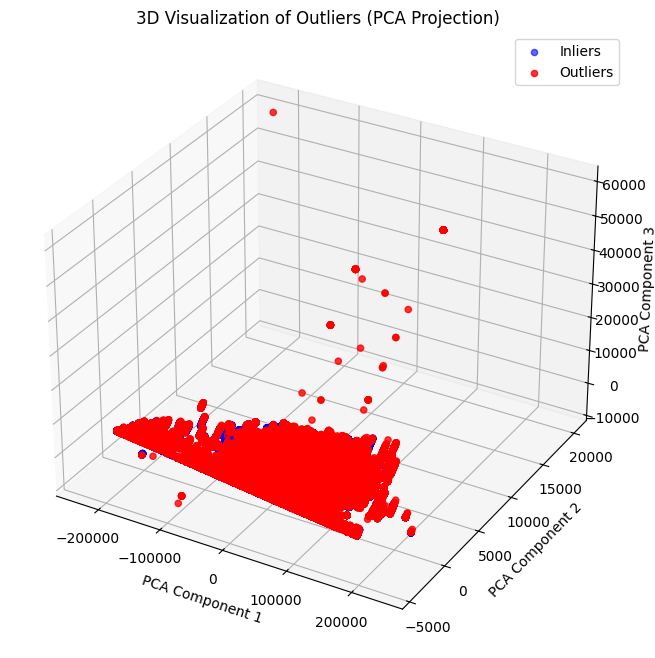

In [38]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso']).fillna(0))

cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]
cop['pca3'] = pca_result[:, 2]

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

inliers = cop[cop['any_outlier'] == 0]
outliers = cop[cop['any_outlier'] == 1]

ax.scatter(inliers['pca1'], inliers['pca2'], inliers['pca3'], c='blue', label='Inliers', alpha=0.6)
ax.scatter(outliers['pca1'], outliers['pca2'], outliers['pca3'], c='red', label='Outliers', alpha=0.8)

ax.set_title('3D Visualization of Outliers (PCA Projection)')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
ax.legend()
plt.show()

Let's for each algortihm what kind of outliers recognize


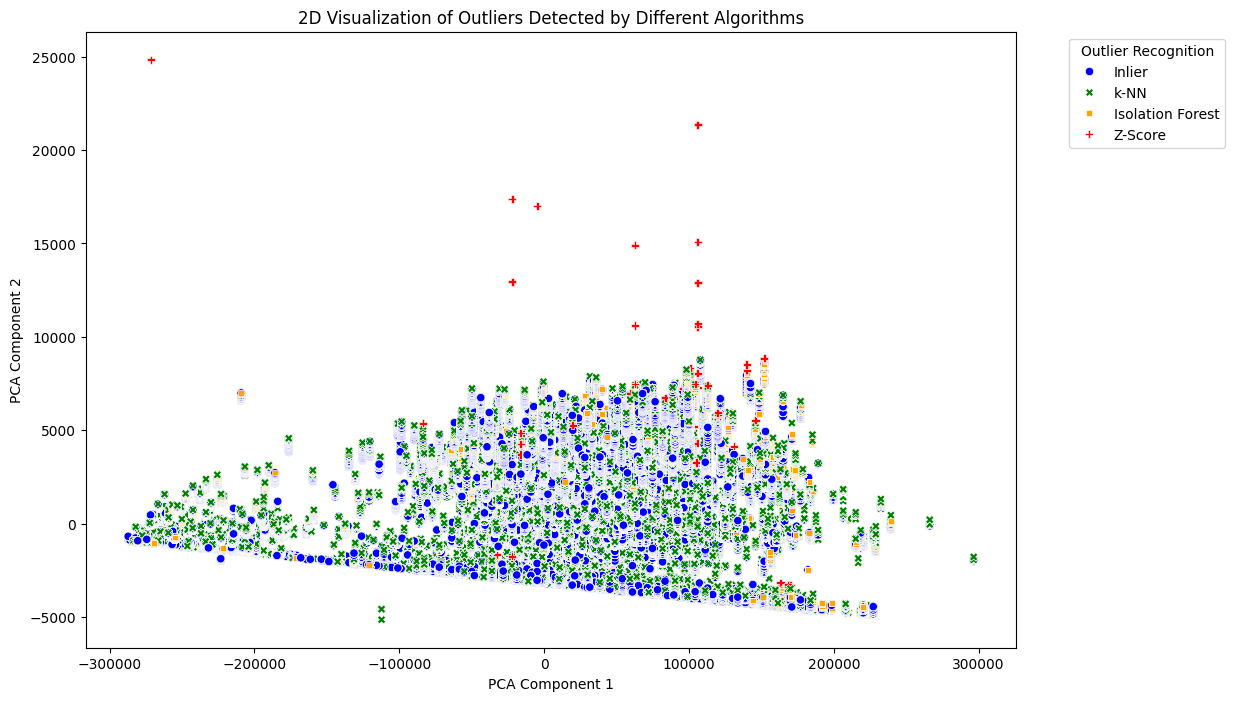

In [39]:
def get_outlier_label(row):
    if row['outlier_zscore']:
        return 'Z-Score'
    elif row['outlier_knn']:
        return 'k-NN'
    elif row['outlier_iso']:
        return 'Isolation Forest'
    return 'Inlier'

cop['outlier_zscore'] = cop.index.isin(zscore_indices).astype(int)
cop['outlier_knn'] = cop.index.isin(knn_indices).astype(int)
cop['outlier_iso'] = cop.index.isin(iso_indices).astype(int)

cop['outlier_label'] = cop.apply(get_outlier_label, axis=1)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso', 'outlier_label']).fillna(0))
cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=cop,
    x='pca1', y='pca2',
    hue='outlier_label',
    palette={'Inlier': 'blue', 'Z-Score': 'red', 'k-NN': 'green', 'Isolation Forest': 'orange'},
    style='outlier_label'
)
plt.title('2D Visualization of Outliers Detected by Different Algorithms')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Outlier Recognition', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

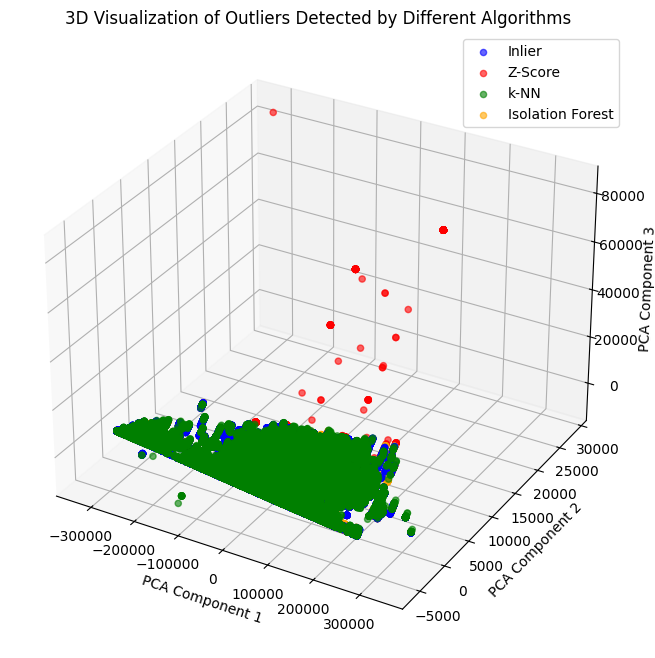

In [40]:
pca = PCA(n_components=3)
pca_result = pca.fit_transform(cop.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso', 'outlier_label']).fillna(0))
cop['pca1'] = pca_result[:, 0]
cop['pca2'] = pca_result[:, 1]
cop['pca3'] = pca_result[:, 2]

# Prepare the figure
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot points based on their outlier labels
colors = {'Inlier': 'blue', 'Z-Score': 'red', 'k-NN': 'green', 'Isolation Forest': 'orange'}
for label, color in colors.items():
    subset = cop[cop['outlier_label'] == label]
    ax.scatter(subset['pca1'], subset['pca2'], subset['pca3'], c=color, label=label, alpha=0.6)

# Add labels and legend
ax.set_title('3D Visualization of Outliers Detected by Different Algorithms')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
ax.legend()
plt.show()

Drop all outliers

In [41]:
df_merged['outlier_zscore'] = df_merged.index.isin(zscore_indices).astype(int)
df_merged['outlier_knn'] = df_merged.index.isin(knn_indices).astype(int)
df_merged['outlier_iso'] = df_merged.index.isin(iso_indices).astype(int)

df_merged['is_outlier'] = (
    df_merged['outlier_zscore'] | 
    df_merged['outlier_knn'] | 
    df_merged['outlier_iso']
).astype(bool)


df_cleaned = df_merged[~df_merged['is_outlier']].copy()

df_cleaned.drop(columns=['outlier_zscore', 'outlier_knn', 'outlier_iso', 'is_outlier'], inplace=True)

print("Shape of the original dataset:", df_merged.shape)
print("Shape of the cleaned dataset:", df_cleaned.shape)

Shape of the original dataset: (589865, 28)
Shape of the cleaned dataset: (499624, 24)


In [42]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 499624 entries, 0 to 589864
Data columns (total 24 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   points               499275 non-null  float64       
 1   uci_points           217942 non-null  float64       
 2   length               499624 non-null  float64       
 3   climb_total          377019 non-null  float64       
 4   profile              405310 non-null  float64       
 5   startlist_quality    499624 non-null  int64         
 6   average_temperature  17943 non-null   float64       
 7   date                 499624 non-null  datetime64[ns]
 8   position             499624 non-null  int64         
 9   cyclist              499624 non-null  object        
 10  cyclist_age          499624 non-null  float64       
 11  is_tarmac            499624 non-null  bool          
 12  cyclist_team         371163 non-null  object        
 13  delta              

## Feature Engeneering

In [43]:
del df_cleaned['birth_year']

In [44]:
df_cleaned['length'] = df_cleaned['length'] / 1000
df_cleaned['climb_total'] = df_cleaned['climb_total'] / 1000

In [45]:
df_cleaned[['length', 'climb_total']]

,length,climb_total
0,162.0,1.101
2,162.0,1.101
4,162.0,1.101
5,162.0,1.101
6,162.0,1.101
...,...,...
589860,8.4,0.060
589861,8.4,0.060
589862,8.4,0.060
589863,8.4,0.060


In [46]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 499624 entries, 0 to 589864
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   points               499275 non-null  float64       
 1   uci_points           217942 non-null  float64       
 2   length               499624 non-null  float64       
 3   climb_total          377019 non-null  float64       
 4   profile              405310 non-null  float64       
 5   startlist_quality    499624 non-null  int64         
 6   average_temperature  17943 non-null   float64       
 7   date                 499624 non-null  datetime64[ns]
 8   position             499624 non-null  int64         
 9   cyclist              499624 non-null  object        
 10  cyclist_age          499624 non-null  float64       
 11  is_tarmac            499624 non-null  bool          
 12  cyclist_team         371163 non-null  object        
 13  delta              

In [47]:
bins = [18, 25, 35, 100]  # Age ranges: 18-25, 26-35, 36+
labels = ['18-25', '26-35', '36+']

# Create the 'age_range' column by binning 'cyclist_age'
df_cleaned['cyclist_age_range'] = pd.cut(df_cleaned['cyclist_age'], bins=bins, labels=labels, right=True)

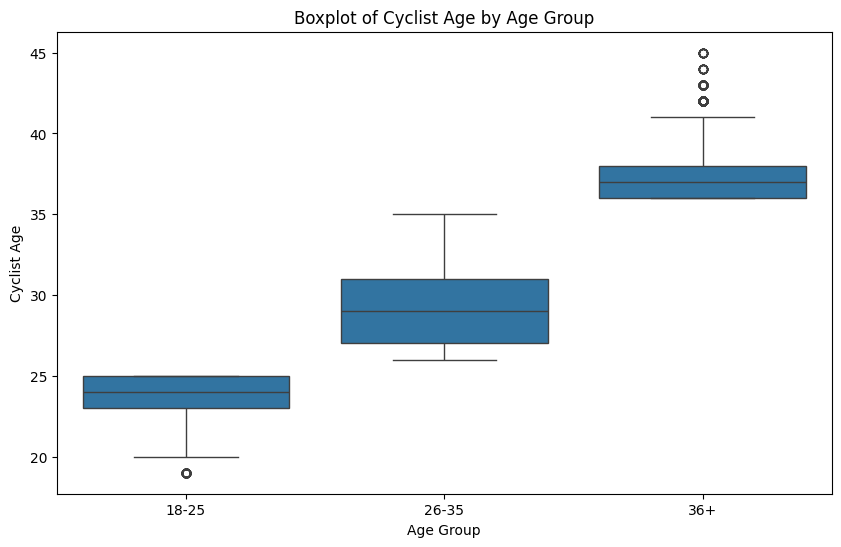

In [48]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_cleaned, x='cyclist_age_range', y='cyclist_age')
plt.title('Boxplot of Cyclist Age by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Cyclist Age')
plt.show()

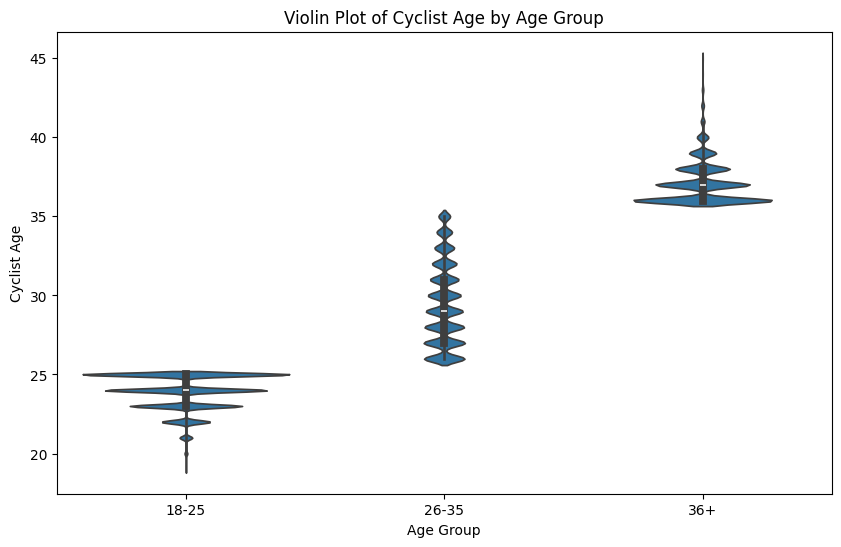

In [49]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_cleaned, x='cyclist_age_range', y='cyclist_age')
plt.title('Violin Plot of Cyclist Age by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Cyclist Age')
plt.show()

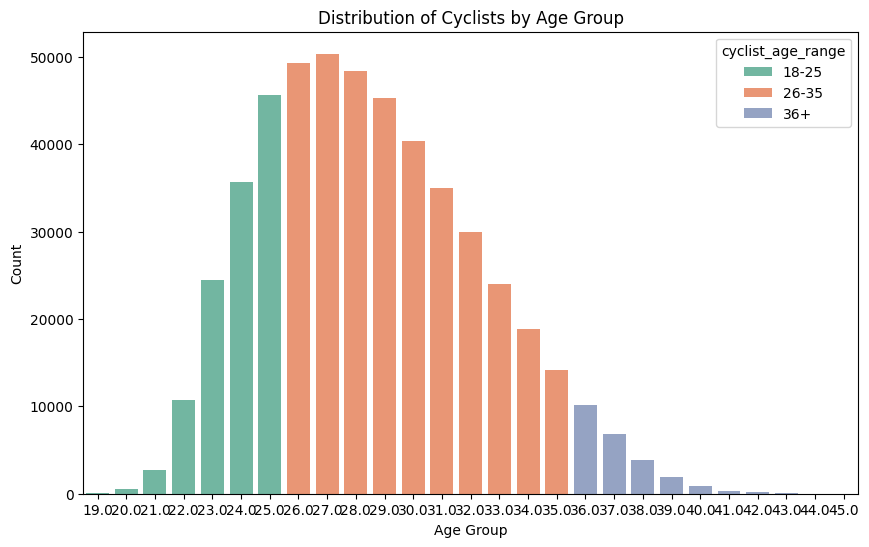

In [50]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_cleaned, x='cyclist_age', palette='Set2', hue="cyclist_age_range")
plt.title('Distribution of Cyclists by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.show()

In [51]:
# Dictionary for country-to-region mapping
country_to_region = {
    # Europe
    'Albania': 'Europe', 'Austria': 'Europe', 'Belarus': 'Europe', 'Belgium': 'Europe',
    'Bulgaria': 'Europe', 'Croatia': 'Europe', 'Czech Republic': 'Europe', 'Denmark': 'Europe',
    'Estonia': 'Europe', 'Finland': 'Europe', 'France': 'Europe', 'Germany': 'Europe',
    'Great Britain': 'Europe', 'Greece': 'Europe', 'Hungary': 'Europe', 'Ireland': 'Europe',
    'Italy': 'Europe', 'Latvia': 'Europe', 'Lithuania': 'Europe', 'Luxembourg': 'Europe',
    'Moldova': 'Europe', 'Monaco': 'Europe', 'Netherlands': 'Europe', 'Norway': 'Europe',
    'Poland': 'Europe', 'Portugal': 'Europe', 'Romania': 'Europe', 'Russia': 'Europe',
    'Serbia': 'Europe', 'Slovakia': 'Europe', 'Slovenia': 'Europe', 'Spain': 'Europe',
    'Sweden': 'Europe', 'Switzerland': 'Europe', 'Ukraine': 'Europe', 'Yugoslavia': 'Europe',

    # Asia
    'Azerbaijan': 'Asia', 'China': 'Asia', 'Iran': 'Asia', 'Israel': 'Asia', 'Japan': 'Asia',
    'Kazakhstan': 'Asia', 'Taiwan': 'Asia', 'Uzbekistan': 'Asia', 'Hongkong': 'Asia',
    
    # Africa
    'Algeria': 'Africa', 'Eritrea': 'Africa', 'Ethiopia': 'Africa', 'Morocco': 'Africa',
    'Namibia': 'Africa', 'Rwanda': 'Africa', 'South Africa': 'Africa', 'Tunisia': 'Africa',
    
    # North America
    'Canada': 'North America', 'Costa Rica': 'North America', 'Guatemala': 'North America',
    'Mexico': 'North America', 'Panama': 'North America', 'Puerto Rico': 'North America',
    'United States': 'North America', 'Dominican Republic': 'North America',

    # South America
    'Argentina': 'South America', 'Brazil': 'South America', 'Chile': 'South America',
    'Colombia': 'South America', 'Ecuador': 'South America', 'Uruguay': 'South America',
    'Venezuela': 'South America', 'Zimbabwe': 'South America',

    # Oceania
    'Australia': 'Oceania', 'New Zealand': 'Oceania',
}

# Map countries to regions in the DataFrame
df_cleaned['region'] = df_cleaned['nationality'].map(country_to_region)

# Check the regional distribution
region_summary = df_cleaned['region'].value_counts()
print(region_summary)

region
Europe           436066
Oceania           19052
North America     18145
South America     15616
Asia               6576
Africa             4169
Name: count, dtype: int64


In [52]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 499624 entries, 0 to 589864
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   points               499275 non-null  float64       
 1   uci_points           217942 non-null  float64       
 2   length               499624 non-null  float64       
 3   climb_total          377019 non-null  float64       
 4   profile              405310 non-null  float64       
 5   startlist_quality    499624 non-null  int64         
 6   average_temperature  17943 non-null   float64       
 7   date                 499624 non-null  datetime64[ns]
 8   position             499624 non-null  int64         
 9   cyclist              499624 non-null  object        
 10  cyclist_age          499624 non-null  float64       
 11  is_tarmac            499624 non-null  bool          
 12  cyclist_team         371163 non-null  object        
 13  delta              

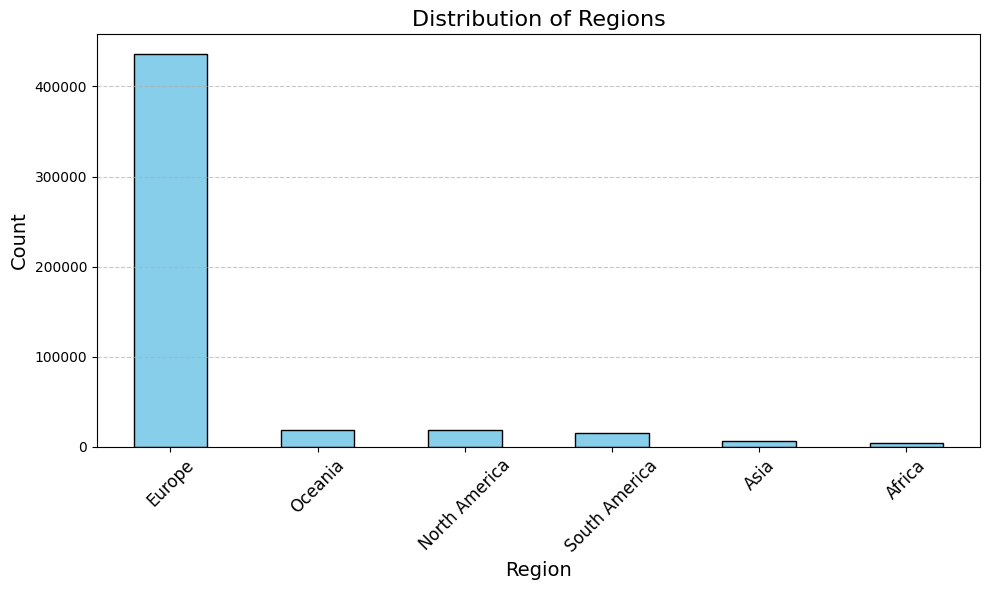

In [53]:
# Count the number of occurrences in each region
region_distribution = df_cleaned['region'].value_counts()

# Plot the distribution
plt.figure(figsize=(10, 6))
region_distribution.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('Region', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.title('Distribution of Regions', fontsize=16)
plt.xticks(rotation=45, fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

<Axes: >

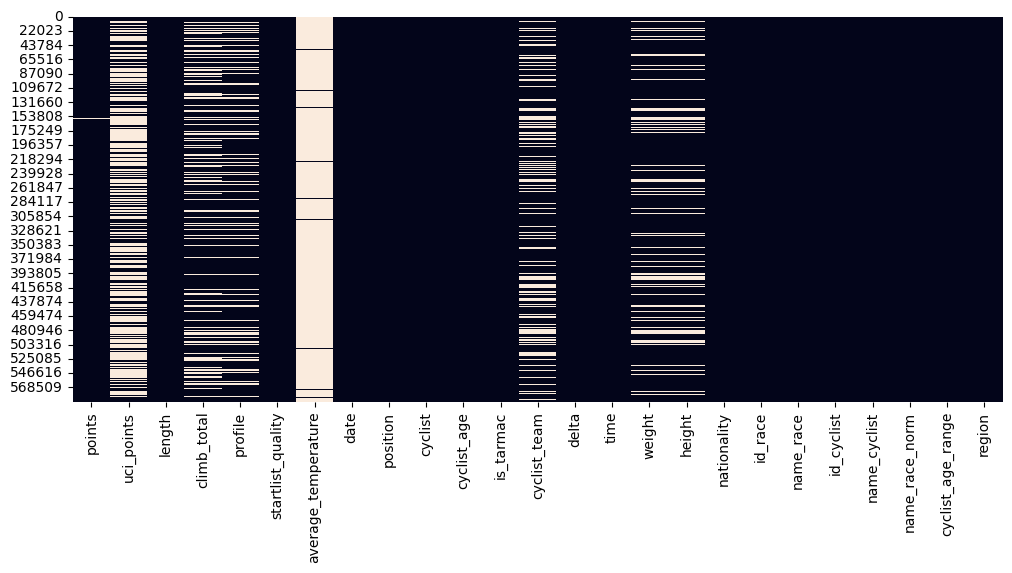

In [54]:
fig, ax = plt.subplots(figsize= (12, 5))
sns.heatmap(df_cleaned.isnull(), cbar=False, xticklabels=True, ax=ax)

We try to fill missing values in climb_total and average_temperature fields searching on web

In [ ]:
# def search_value(html_text, field):
#     soup = BeautifulSoup(html_text, 'html.parser')
#     target_div = soup.find('div', string=field)
#     if target_div == None:
#         return None
#     parent_li = target_div.find_parent('li')
#     if parent_li == None:
#         return None
#     second_div = parent_li.find_all('div')[1]
#     value = second_div.text.strip()
#     if value == '':
#         return None
#     return value


# climb_total = 'climb_total'
# average_temperature = 'average_temperature'
# wb_climb_total = 'Vertical meters:'
# wb_average_temperature = 'Avg. temperature:'

# df_unique = df_cleaned.drop_duplicates(subset='id_race', keep='first')
# df = df_unique[df_unique[climb_total].isnull() | df_unique[average_temperature].isnull()]
# filled = 0

# # File path
# file_cached = '../dataset/df_cached.csv'

# if not os.path.exists(file_cached):
#     for index, row in  tqdm(df.iterrows(), total=df.shape[0]):
#         url = f'https://www.procyclingstats.com/race/{df.at[index, 'id_race']}'
#         response = r.get(url)
#         if response.status_code != 200:
#             print('response error')
#             continue
#         if pd.isnull(row[climb_total]) == True:
#             value = search_value(response.text, wb_climb_total)
#             if value != None:
#                 df.at[index, climb_total] = value
#                 print('filled climb_total')
#                 filled += 1
#         if pd.isnull(row[average_temperature]) == True:
#             value = search_value(response.text, wb_average_temperature)
#             if value != None:
#                 df.at[index, wb_average_temperature] = value
#                 print('filled average_temperature')
#                 filled += 1
#     df.to_csv(file_cached, index=False)


- The previous script found values for the **average_temperature** of some rides. Due to the large amount of missing values in the **average_temperature** field, despite trying to fill, we delete this column.
- For **height** and **weight** fields, we fill the values with the mean because the their distribution is normal.
- Fill the missing values for **climb_total** with -1 value.
- We drop **cyclist_team** feature because we cannot fill the missing values.
- We fill **points** missing values with the median.

In [55]:
df_cleaned['height'].fillna(df_cleaned['height'].mean(), inplace=True)
df_cleaned['weight'].fillna(df_cleaned['weight'].mean(), inplace=True)
df_cleaned['points'].fillna(df_cleaned['points'].median(), inplace=True)
df_cleaned['profile'].fillna(-1, inplace=True)
df_cleaned['climb_total'].fillna(-1, inplace=True)

/tmp/ipykernel_36328/2380145684.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_cleaned['height'].fillna(df_cleaned['height'].mean(), inplace=True)
/tmp/ipykernel_36328/2380145684.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(val

We discretize the following features:
- cyclist_points
- startlist_quality
- position

In [56]:
bins = [0, 50, 150, 250, 350]  # Cyclist points ranges: 0-50, 50-150, 150-250, 250-350
labels = ['entry', 'medium', 'advanced', 'top']
# Create the 'cyclist_points_range' column by binning 'cyclist_points'
df_cleaned['cyclist_points_range'] = pd.cut(df_cleaned['points'], bins=bins, labels=labels, right=True)


bins = [0, 500, 1000, 1500, 2500]  # Startlist quality ranges: 0-500, 500-1000, 1000-1500, 1500-2500
labels = ['entry', 'medium', 'advanced', 'top']
# Create the 'startlist_quality_range' column by binning 'startlist_quality'
df_cleaned['startlist_quality_range'] = pd.cut(df_cleaned['startlist_quality'], bins=bins, labels=labels, right=True)


bins = [-1, 50, 100, 150, 200]  # Position ranges: 0-50, 50-100, 100-150, 150-200
labels = ['top', 'advanced', 'medium', 'entry']
# Create the 'position_range' column by binning 'position'
df_cleaned['position_range'] = pd.cut(df_cleaned['position'], bins=bins, labels=labels, right=True)

In [57]:
print(df_cleaned['cyclist_points_range'].unique())
print(df_cleaned['startlist_quality_range'].unique())
print(df_cleaned['position_range'].unique())

['medium', 'entry', 'top', 'advanced']
Categories (4, object): ['entry' < 'medium' < 'advanced' < 'top']
['advanced', 'medium', 'top', 'entry']
Categories (4, object): ['entry' < 'medium' < 'advanced' < 'top']
['top', 'advanced', 'medium', 'entry', NaN]
Categories (4, object): ['top' < 'advanced' < 'medium' < 'entry']


We encode the following feature from string to int.

In [58]:

from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df_cleaned['region'] = label_encoder.fit_transform(df_cleaned['region'])
label_encoder = LabelEncoder()
df_cleaned['cyclist_age_range'] = label_encoder.fit_transform(df_cleaned['cyclist_age_range'])
label_encoder = LabelEncoder()
df_cleaned['cyclist_points_range'] = label_encoder.fit_transform(df_cleaned['cyclist_points_range'])
label_encoder = LabelEncoder()
df_cleaned['startlist_quality_range'] = label_encoder.fit_transform(df_cleaned['startlist_quality_range'])
label_encoder = LabelEncoder()
df_cleaned['position_range'] = label_encoder.fit_transform(df_cleaned['position_range'])

We normalize the following features.

In [ ]:
normalized_dataset, normalization_scalers_dataset = center_and_scale(df_cleaned)
df_cleaned['points'] = normalized_dataset['points']
df_cleaned['length'] = normalized_dataset['length']
df_cleaned['startlist_quality'] = normalized_dataset['startlist_quality']
df_cleaned['weight'] = normalized_dataset['weight']
df_cleaned['height'] = normalized_dataset['height']

In [60]:
import pickle

dict_scaler = {
    "normalized_dataset": normalized_dataset,
    "scalers": normalization_scalers_dataset
}

with open(f"transformations/dict_scalers.pkl", "wb") as f:
    pickle.dump(dict_scaler, f)

In [61]:
df_cleaned['date_for_splitting'] = pd.to_datetime(df_cleaned['date'])
df_cleaned = df_cleaned[df_cleaned['date_for_splitting'].dt.year >= 2000]

In [62]:
print(df_cleaned['cyclist_points_range'].unique())
print(df_cleaned['startlist_quality_range'].unique())
print(df_cleaned['position_range'].unique())

[2 1 3 0]
[2 3 0 1]
[3 0 2 1 4]


In [63]:
df_cleaned['date'] = pd.to_datetime(df_cleaned['date'])
top_placement = 20

profile = df_cleaned["profile"].unique()
for p in profile:
    df_cleaned[f"profile_score_{p}"] = 0
    df_cleaned[f"mode_position_for_{p}"] = 3


In [64]:
for index, row in df_cleaned.iterrows():
    clear_output()
    print(index, ' of ', 589864)
    df_for_feature = df_cleaned[
        (df_cleaned["id_cyclist"] == row['id_cyclist']) & 
        (df_cleaned["date"].dt.year < row['date'].year) &
        (df_cleaned["date"].dt.year > row['date'].year - 5)
    ]
    
    cyclist_stats = df_for_feature.groupby('id_cyclist').agg(
        median_points=('points', 'median'),
        median_startlist=('startlist_quality', 'median'),

        mode_position=('position_range', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
        mode_startlist_quality=('startlist_quality_range', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
        mode_points=('cyclist_points_range', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    ).reset_index()
    
    mode_points = -1 if not len(cyclist_stats) else cyclist_stats[cyclist_stats['id_cyclist'] == row['id_cyclist']]['mode_points'].iat[0]
    mode_position = -1 if not len(cyclist_stats) else cyclist_stats[cyclist_stats['id_cyclist'] == row['id_cyclist']]['mode_position'].iat[0]
    mode_startlist_quality = -1 if not len(cyclist_stats) else cyclist_stats[cyclist_stats['id_cyclist'] == row['id_cyclist']]['mode_startlist_quality'].iat[0]
    median_points = -1 if not len(cyclist_stats) else cyclist_stats[cyclist_stats['id_cyclist'] == row['id_cyclist']]['median_points'].iat[0]
    median_startlist = -1 if not len(cyclist_stats) else cyclist_stats[cyclist_stats['id_cyclist'] == row['id_cyclist']]['median_startlist'].iat[0]
    
    df_cleaned.at[index, "mode_points"] = mode_points
    df_cleaned.at[index, "mode_position"] = mode_position
    df_cleaned.at[index, "mode_startlist_quality"] = mode_startlist_quality
    df_cleaned.at[index, "median_points"] = median_points
    df_cleaned.at[index, "median_startlist"] = median_startlist

99323  of  589864


In [ ]:
for index, row in df_cleaned.iterrows():
    clear_output()
    print(index, ' of ', 589864)
    df_for_feature = df_cleaned[
        (df_cleaned["id_cyclist"] == row['id_cyclist']) & 
        (df_cleaned["date"].dt.year < row['date'].year) &
        (df_cleaned["date"].dt.year > row['date'].year - 5)
    ]
    
    placement_points = df_for_feature[
        df_for_feature["position"] > top_placement
    ]['points'].sum()
    total_points = df_for_feature['points'].sum()

    placement_startlist_quality = df_for_feature[
        df_for_feature["position"] > top_placement
    ]['startlist_quality'].sum()
    total_startlist_quality = df_for_feature['startlist_quality'].sum()

    df_cleaned.at[index, "placement_points"] = placement_points / total_points if total_points != 0 else 0
    df_cleaned.at[index, "placement_startlist_quality"] = placement_startlist_quality / total_startlist_quality if total_startlist_quality != 0 else 0

589864  of  589864


In [ ]:
for index, row in df_cleaned.iterrows():
    clear_output()
    print(index, ' of ', 589864)
    df_for_feature = df_cleaned[
        (df_cleaned["id_cyclist"] == row['id_cyclist']) &
        (df_cleaned["date"].dt.year < row['date'].year) &
        (df_cleaned["date"].dt.year > row['date'].year - 5)
    ]
    
    cyclist_stats_profile = df_for_feature.groupby('profile').agg(
        mode_position=('position_range', lambda x: x.mode().iloc[0] if not x.mode().empty else None),
    ).reset_index()

    for p in profile:
        score = len(
            df_for_feature[
                (df_for_feature["profile"] == p) & 
                (df_for_feature["position_range"] == 0)
            ]
        )
        total_score = len(
            df_for_feature[
                (df_for_feature["position_range"] == 0)
            ]
        )
        mode_position = -1 if not len(cyclist_stats_profile[cyclist_stats_profile['profile'] == p]) else cyclist_stats_profile[cyclist_stats_profile['profile'] == p]['mode_position'].iat[0]

        df_cleaned.at[index, f"profile_score_{p}"] = score / total_score if total_score != 0 else 0
        df_cleaned.at[index, f"mode_position_for_{p}"] = mode_position

589864  of  589864


In [ ]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 380091 entries, 106 to 589864
Data columns (total 48 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   points                       380091 non-null  float64       
 1   uci_points                   217942 non-null  float64       
 2   length                       380091 non-null  float64       
 3   climb_total                  380091 non-null  float64       
 4   profile                      380091 non-null  float64       
 5   startlist_quality            380091 non-null  float64       
 6   average_temperature          17943 non-null   float64       
 7   date                         380091 non-null  datetime64[ns]
 8   position                     380091 non-null  int64         
 9   cyclist                      380091 non-null  object        
 10  cyclist_age                  380091 non-null  float64       
 11  is_tarmac               

In [ ]:
df_cleaned.head()

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,...,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
106,-0.106818,100.0,0.49384,5.575,5.0,-0.742775,NaN,2016-09-03,0,robert-gesink,...,-1,2.0,3,2.0,3.0,2.0,-0.106818,-0.384245,0.611283,0.863722
107,-0.106818,100.0,0.49384,5.575,5.0,-0.742775,NaN,2016-09-03,1,kenny-elissonde,...,-1,7.0,0,2.0,3.0,2.0,-0.106818,-0.347065,0.955445,0.988797
108,-0.106818,100.0,0.49384,5.575,5.0,-0.742775,NaN,2016-09-03,2,egor-silin,...,-1,0.0,3,1.0,0.0,2.0,-0.735134,-0.487821,0.920567,0.910897
109,-0.106818,100.0,0.49384,5.575,5.0,-0.742775,NaN,2016-09-03,3,george-bennett,...,-1,0.0,0,1.0,0.0,2.0,-0.735134,-0.347065,0.936264,0.962458
110,-0.106818,100.0,0.49384,5.575,5.0,-0.742775,NaN,2016-09-03,4,simon-yates,...,-1,0.0,3,1.0,3.0,2.0,0.312060,0.320862,1.112433,0.956625


In [ ]:
# df_cleaned.to_csv(cleaned_dataset, index=False)